# ASVspoof 2019 LA: DSP spoof-speech detection with a threshold

**Question:** Can a simple DSP pipeline classify speech as `bonafide` or `spoof`?

**Input:** 16 kHz ASVspoof 2019 LA FLAC audio. **Output:** one predicted label per recording.

Main pipeline: `audio -> 100-4000 Hz band-pass -> mean MFCC coefficient 8 -> threshold if/else -> label`.

> Band-pass + MFCC coefficient 8 was the best threshold-based result in the exploratory sweep (eval balanced accuracy 0.775). Filter/feature choice used the eval sweep, so report this as exploratory, not as an independent final test.


## 1. Setup and dependencies


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
from scipy.signal import butter, sosfiltfilt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score

plt.rcParams["font.family"] = "Tahoma"

CODE_DIR = Path.cwd()
if not (CODE_DIR.parent / "1_data" / "ground_truth" / "labels.csv").is_file() and (CODE_DIR / "2_code").is_dir():
    CODE_DIR = CODE_DIR / "2_code"
DATA = CODE_DIR.parent / "1_data"
RESULTS = CODE_DIR / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 16_000
FILTER_LOW_HZ = 100
FILTER_HIGH_HZ = 4_000
FILTER_ORDER = 4
N_MFCC = 13
MFCC_INDEX = 7  # index 7 ??? coefficient ???????? 8
HOP_LENGTH = 256
N_FFT = 512


## 2. Load data and validate train/eval splits


In [2]:
gt = pd.read_csv(DATA / "ground_truth" / "labels.csv", dtype={"id": str, "label": str})
gt["split"] = gt["file"].map(lambda value: value.split("/")[1])
gt = gt[gt["split"].isin(["train", "eval"])].copy()

assert set(gt["split"]) == {"train", "eval"}
assert set(gt["label"]) == {"bonafide", "spoof"}
missing = [DATA / "raw" / name for name in gt["file"] if not (DATA / "raw" / name).is_file()]
assert not missing, f"?????????????? {len(missing)} ????"

counts = gt.groupby(["split", "label"]).size().unstack(fill_value=0)
counts


label,bonafide,spoof
split,,
eval,775,775
train,2350,2350


## 3. EDA: class counts and example audio


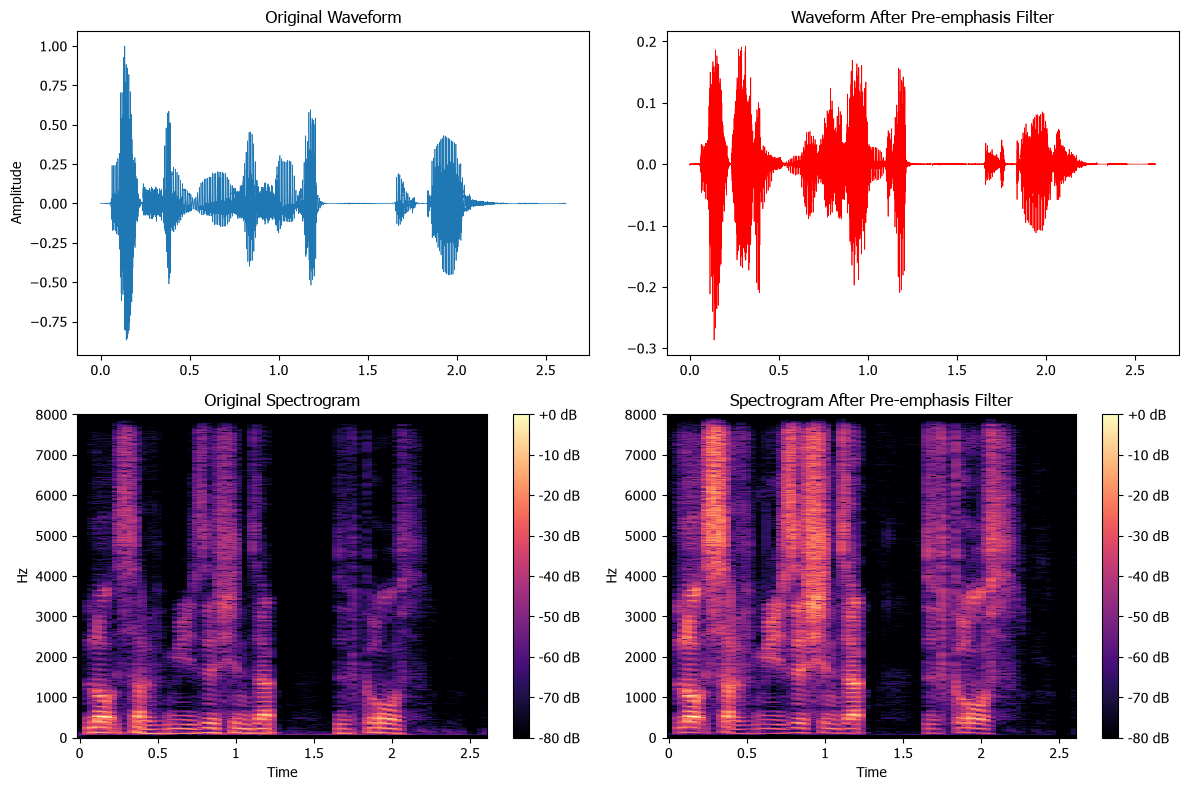

In [23]:
def plot_filter_comparison(y_original, y_filtered, sr, filter_name):
    fig, ax = plt.subplots(2, 2, figsize=(12, 8))
    
    time = np.arange(len(y_original)) / sr
    ax[0, 0].plot(time, y_original, linewidth=0.5)
    ax[0, 0].set_title("Original Waveform")
    ax[0, 0].set_ylabel("Amplitude")
    
    ax[0, 1].plot(time, y_filtered, linewidth=0.5, color='r')
    ax[0, 1].set_title(f"Waveform After {filter_name}")
    
    D_orig = librosa.amplitude_to_db(np.abs(librosa.stft(y_original)), ref=np.max)
    D_filt = librosa.amplitude_to_db(np.abs(librosa.stft(y_filtered)), ref=np.max)
    
    img1 = librosa.display.specshow(D_orig, sr=sr, x_axis='time', y_axis='hz', ax=ax[1, 0])
    ax[1, 0].set_title("Original Spectrogram")
    fig.colorbar(img1, ax=ax[1, 0], format="%+2.0f dB")
    
    img2 = librosa.display.specshow(D_filt, sr=sr, x_axis='time', y_axis='hz', ax=ax[1, 1])
    ax[1, 1].set_title(f"Spectrogram After {filter_name}")
    fig.colorbar(img2, ax=ax[1, 1], format="%+2.0f dB")
    
    plt.tight_layout()
    plt.savefig(FIGURES / "preemphasis_comparison.png", dpi=160) 
    plt.show()

sample_item = gt[gt["label"] == "spoof"].iloc[0].to_dict()
audio, sr = read_audio(sample_item)

filtered_audio = filter_preemphasis(audio)
plot_filter_comparison(audio, filtered_audio, sr, "Pre-emphasis Filter")

## 4. Main pipeline

1. Read 16 kHz audio; average stereo channels to mono when necessary.
2. Apply a fourth-order Butterworth band-pass from 100 to 4,000 Hz using zero-phase `sosfiltfilt`.
3. Calculate 13 MFCCs (`n_fft=512`, `hop_length=256`) and average coefficient 8 over time.
4. Choose a threshold using train balanced accuracy, then use an `if/else` rule for predictions.

The filter is intended to remove frequencies outside the selected band before feature extraction.


In [3]:
def bandpass(audio, sr):
    sos = butter(
        FILTER_ORDER,
        [FILTER_LOW_HZ, FILTER_HIGH_HZ],
        btype="bandpass",
        fs=sr,
        output="sos",
    )
    return sosfiltfilt(sos, audio).astype(np.float32, copy=False)

def filter_preemphasis(audio, coef=0.97):
    return librosa.effects.preemphasis(audio, coef=coef).astype(np.float32, copy=False)

def mfcc8_mean(audio, sr):
    coefficients = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
    )
    return float(np.mean(coefficients[MFCC_INDEX]))


def choose_threshold(values, labels):
    """Choose direction/threshold maximizing balanced accuracy on train only."""
    values = np.asarray(values, dtype=float)
    targets = np.asarray([label == "spoof" for label in labels], dtype=int)
    order = np.argsort(values)
    sorted_values = values[order]
    sorted_targets = targets[order]
    positive_count = int(targets.sum())
    negative_count = len(targets) - positive_count
    if positive_count == 0 or negative_count == 0:
        raise ValueError("Train must contain both bonafide and spoof examples")

    midpoints = (sorted_values[:-1] + sorted_values[1:]) / 2
    epsilon = max(1e-12, abs(float(sorted_values[0])) * 1e-12)
    thresholds = np.unique(np.concatenate((
        [sorted_values[0] - epsilon], midpoints, [sorted_values[-1] + epsilon]
    )))
    prefix_positive = np.concatenate(([0], np.cumsum(sorted_targets)))
    best = None
    for direction in ("ge", "lt"):
        for threshold in thresholds:
            split_index = int(np.searchsorted(sorted_values, threshold, side="left"))
            positive_below = int(prefix_positive[split_index])
            if direction == "ge":
                true_positive = positive_count - positive_below
                true_negative = split_index - positive_below
            else:
                true_positive = positive_below
                true_negative = negative_count - (split_index - positive_below)
            balanced_accuracy = 0.5 * (
                true_positive / positive_count + true_negative / negative_count
            )
            candidate = (float(balanced_accuracy), direction, float(threshold))
            if best is None or candidate[0] > best[0]:
                best = candidate
    assert best is not None
    return best[2], best[1], best[0]


def decide(value, threshold, direction):
    if direction == "lt":
        return "spoof" if value < threshold else "bonafide"
    return "spoof" if value >= threshold else "bonafide"


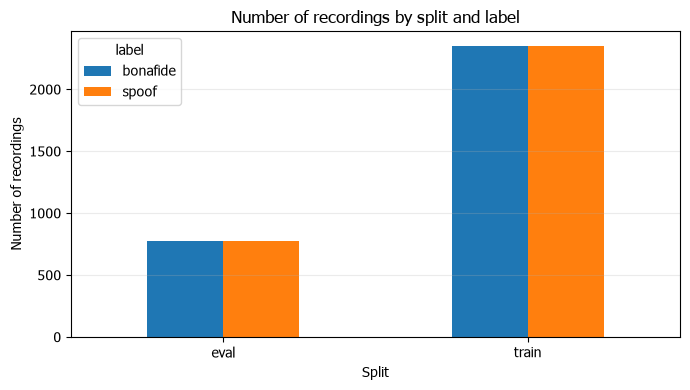

Total recordings: 6,250
Dataset sampling rate: 16,000 Hz


In [15]:
ax = counts.plot.bar(figsize=(7, 4), rot=0)
ax.set_title("Number of recordings by split and label")
ax.set_xlabel("Split")
ax.set_ylabel("Number of recordings")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Total recordings: {len(gt):,}")
print("Dataset sampling rate: 16,000 Hz")


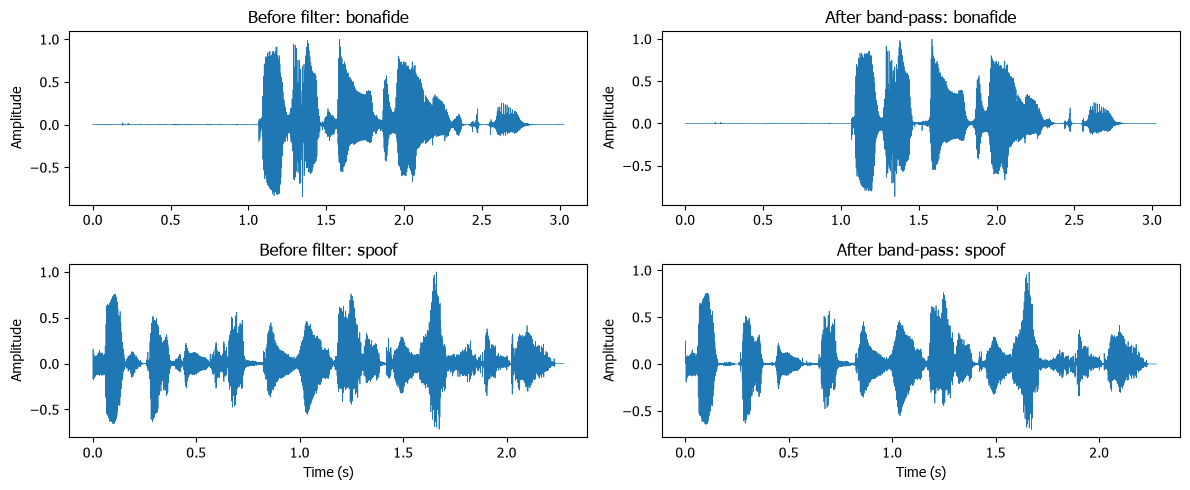

In [4]:
def read_audio(item):
    audio, sr = sf.read(DATA / "raw" / item["file"], dtype="float32")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if sr != SAMPLE_RATE:
        raise ValueError(f"Expected {SAMPLE_RATE} Hz, got {sr} Hz: {item['file']}")
    if audio.size == 0 or not np.isfinite(audio).all():
        raise ValueError(f"Empty or non-finite signal: {item['file']}")
    return audio, sr

sample_items = [
    gt[(gt["split"] == "eval") & (gt["label"] == label)].iloc[0].to_dict()
    for label in ["bonafide", "spoof"]
]
fig, axes = plt.subplots(2, 2, figsize=(12, 5))
for row_index, item in enumerate(sample_items):
    audio, sr = read_audio(item)
    filtered = bandpass(audio, sr)
    time = np.arange(len(audio)) / sr
    axes[row_index, 0].plot(time, audio, linewidth=0.5)
    axes[row_index, 0].set_title(f"Before filter: {item['label']}")
    axes[row_index, 1].plot(time, filtered, linewidth=0.5)
    axes[row_index, 1].set_title(f"After band-pass: {item['label']}")
    axes[row_index, 0].set_ylabel("Amplitude")
    axes[row_index, 1].set_ylabel("Amplitude")
for axis in axes[-1, :]:
    axis.set_xlabel("Time (s)")
plt.tight_layout()
figure_path = FIGURES / "bandpass_before_after.png"
plt.savefig(figure_path, dpi=160)
plt.show()


## 5. Fit the train threshold and evaluate once on eval


In [17]:
feature_rows = []
for index, item in enumerate(gt.to_dict("records"), start=1):
    audio, sr = read_audio(item)
    filtered = bandpass(audio, sr)
    feature_rows.append({
        "id": item["id"],
        "split": item["split"],
        "label": item["label"],
        "condition": item["condition"],
        "attack_id": item["attack_id"],
        "mfcc_8": mfcc8_mean(filtered, sr),
    })
    if index % 500 == 0 or index == len(gt):
        print(f"Processed {index:,}/{len(gt):,} recordings")

features = pd.DataFrame(feature_rows)
train = features[features["split"] == "train"]
evaluation = features[features["split"] == "eval"]
threshold, direction, train_balanced_accuracy = choose_threshold(
    train["mfcc_8"].to_numpy(), train["label"].tolist()
)
print(f"Train rule: MFCC_8 {direction} {threshold:.6f}")
print(f"Train balanced accuracy: {train_balanced_accuracy:.3f}")


Processed 500/6,250 recordings
Processed 1,000/6,250 recordings
Processed 1,500/6,250 recordings
Processed 2,000/6,250 recordings
Processed 2,500/6,250 recordings
Processed 3,000/6,250 recordings
Processed 3,500/6,250 recordings
Processed 4,000/6,250 recordings
Processed 4,500/6,250 recordings
Processed 5,000/6,250 recordings
Processed 5,500/6,250 recordings
Processed 6,000/6,250 recordings
Processed 6,250/6,250 recordings
Train rule: MFCC_8 lt -19.426172
Train balanced accuracy: 0.698


In [18]:
eval_results = evaluation.copy()
eval_results["predicted"] = [
    decide(value, threshold, direction) for value in eval_results["mfcc_8"]
]
eval_results["correct"] = eval_results["label"] == eval_results["predicted"]

y_true = eval_results["label"]
y_pred = eval_results["predicted"]
cm = confusion_matrix(y_true, y_pred, labels=["bonafide", "spoof"])
metrics = pd.DataFrame([{
    "filter": "bandpass_100_4000hz",
    "feature": "mfcc_8",
    "threshold": threshold,
    "direction": direction,
    "train_balanced_accuracy": train_balanced_accuracy,
    "eval_accuracy": accuracy_score(y_true, y_pred),
    "eval_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    "eval_macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "n_eval": len(eval_results),
    "n_correct": int(eval_results["correct"].sum()),
    "n_errors": int((~eval_results["correct"]).sum()),
}])
metrics


,filter,feature,threshold,direction,train_balanced_accuracy,eval_accuracy,eval_balanced_accuracy,eval_macro_f1,n_eval,n_correct,n_errors
0,bandpass_100_4000hz,mfcc_8,-19.426172,lt,0.698085,0.775484,0.775484,0.775231,1550,1202,348


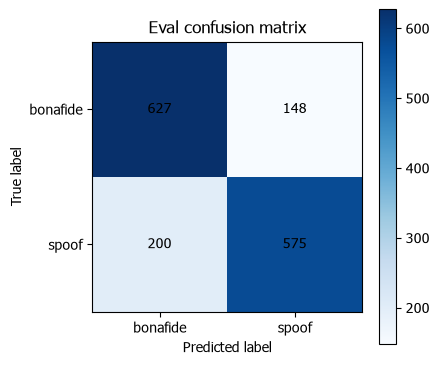

In [19]:
fig, ax = plt.subplots(figsize=(4.5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["bonafide", "spoof"])
ax.set_yticks([0, 1], ["bonafide", "spoof"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Eval confusion matrix")
for (row, column), value in np.ndenumerate(cm):
    ax.text(column, row, str(value), ha="center", va="center")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.savefig(FIGURES / "threshold_confusion_matrix.png", dpi=160)
plt.show()

RESULTS.mkdir(parents=True, exist_ok=True)
metrics.to_csv(RESULTS / "threshold_pipeline_metrics.csv", index=False)
eval_results.to_csv(RESULTS / "threshold_pipeline_predictions.csv", index=False)


## 6. Compare other filter/feature experiments


,filter,feature,threshold,direction,train_balanced_accuracy,eval_accuracy,eval_balanced_accuracy,eval_macro_f1,eval_spoof_recall,eval_bonafide_recall,tn,fp,fn,tp
15,bandpass_100_4000hz,mfcc_8,-19.426172,lt,0.698085,0.775484,0.775484,0.775231,0.741935,0.809032,627,148,200,575
7,lowpass_4000hz,mfcc_8,-15.356819,lt,0.704894,0.772258,0.772258,0.771928,0.734194,0.810323,628,147,206,569
3,no_filter,mfcc_8,-11.325475,lt,0.699574,0.696129,0.696129,0.686253,0.518710,0.873548,677,98,373,402
11,highpass_100hz,mfcc_6,-4.505647,lt,0.684468,0.652258,0.652258,0.644636,0.505806,0.798710,619,156,383,392
0,no_filter,rms,0.128314,ge,0.555745,0.648387,0.648387,0.641358,0.508387,0.788387,611,164,381,394
4,lowpass_4000hz,rms,0.129620,ge,0.556383,0.645806,0.645806,0.635633,0.478710,0.812903,630,145,404,371
5,lowpass_4000hz,zcr,0.077636,ge,0.521915,0.638065,0.638065,0.630274,0.783226,0.492903,382,393,168,607
1,no_filter,zcr,0.125806,ge,0.537234,0.632903,0.632903,0.632406,0.596129,0.669677,519,256,313,462
8,highpass_100hz,rms,0.150320,ge,0.554894,0.610968,0.610968,0.558351,0.265806,0.956129,741,34,569,206
12,bandpass_100_4000hz,rms,0.149750,ge,0.555745,0.609677,0.609677,0.556887,0.264516,0.954839,740,35,570,205


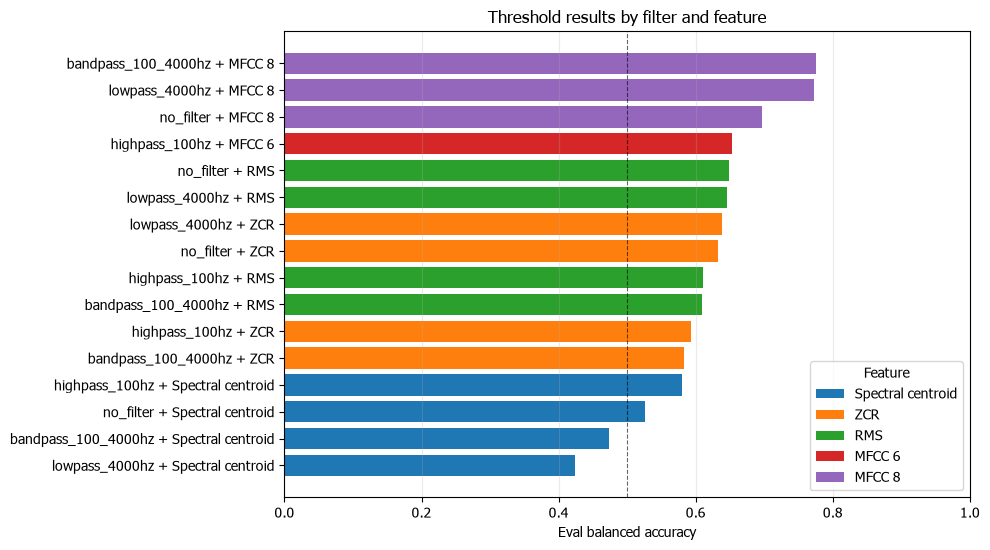

In [2]:
comparison_path = RESULTS / "filter_experiment" / "metrics.csv"
if comparison_path.is_file():
    comparison = pd.read_csv(comparison_path)
    display(comparison.sort_values("eval_balanced_accuracy", ascending=False))

    feature_labels = {
        "rms": "RMS",
        "zcr": "ZCR",
        "centroid": "Spectral centroid",
        "mfcc_6": "MFCC 6",
        "mfcc_8": "MFCC 8",
    }
    comparison["feature_label"] = comparison["feature"].map(feature_labels).fillna(comparison["feature"])
    comparison["method"] = comparison["filter"] + " + " + comparison["feature_label"]
    plot_data = comparison.sort_values("eval_balanced_accuracy").reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(10, max(5, 0.35 * len(plot_data))))
    for feature_label, feature_rows in plot_data.groupby("feature_label", sort=False):
        ax.barh(
            feature_rows.index,
            feature_rows["eval_balanced_accuracy"],
            label=feature_label,
        )
    ax.set_yticks(range(len(plot_data)), plot_data["method"])
    ax.set_xlim(0, 1)
    ax.axvline(0.5, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    ax.set_xlabel("Eval balanced accuracy")
    ax.set_ylabel("")
    ax.set_title("Threshold results by filter and feature")
    ax.legend(title="Feature", loc="lower right")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.savefig(FIGURES / "threshold_filter_feature_comparison.png", dpi=160)
    plt.show()
else:
    print(f"Comparison results not found: {comparison_path}; skipping comparison table")

## 7. Failure cases and conclusion


In [21]:
errors = eval_results[~eval_results["correct"]].copy()
false_positive = errors[(errors["label"] == "bonafide") & (errors["predicted"] == "spoof")]
false_negative = errors[(errors["label"] == "spoof") & (errors["predicted"] == "bonafide")]
selected = []
if len(false_positive):
    selected.append(false_positive.iloc[0])
if len(false_negative):
    selected.append(false_negative.iloc[0])
for _, row in errors.iterrows():
    if len(selected) >= 3:
        break
    if all(row["id"] != chosen["id"] for chosen in selected):
        selected.append(row)

failure_cases = pd.DataFrame(selected)[[
    "id", "condition", "attack_id", "label", "predicted", "mfcc_8"
]].rename(columns={"label": "expected"})
failure_cases["failed_stage"] = "threshold if/else decision"
failure_cases


,id,condition,attack_id,expected,predicted,mfcc_8,failed_stage
4718,LA_E_5628684,bonafide,-,bonafide,spoof,-19.523476,threshold if/else decision
5476,LA_E_1315822,A16,A16,spoof,bonafide,-15.798635,threshold if/else decision
4724,LA_E_3526157,bonafide,-,bonafide,spoof,-26.052511,threshold if/else decision


In [22]:
failure_cases.to_csv(RESULTS / "threshold_pipeline_failure_cases.csv", index=False)
print(f"Eval correct: {int(metrics.loc[0, 'n_correct'])}/{int(metrics.loc[0, 'n_eval'])}")
print(f"Balanced accuracy: {metrics.loc[0, 'eval_balanced_accuracy']:.3f}")
print(f"Macro-F1: {metrics.loc[0, 'eval_macro_f1']:.3f}")
print("Main pipeline: band-pass + MFCC coefficient 8 + threshold if/else")
print("Limitation: filter/feature selection used the exploratory eval sweep; report as preliminary.")


Eval correct: 1202/1550
Balanced accuracy: 0.775
Macro-F1: 0.775
Main pipeline: band-pass + MFCC coefficient 8 + threshold if/else
Limitation: filter/feature selection used the exploratory eval sweep; report as preliminary.
